https://drive.google.com/file/d/158xdQJggURo9IlVBXxMad6rCjvhaW2Sz/view?usp=sharing

link file data(nặng quá e k cho lên github đc)

In [158]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [159]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import csv

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error



df = pd.read_csv(
    '/content/drive/MyDrive/TMDB_movie_dataset_v11 (1).csv',
    sep=',',
    quotechar='"',
    on_bad_lines='skip',  #Bỏ qua các dòng bị lỗi xuống dòng or ngoặc kép trong văn bản
    engine='python'
)
#do dữ liệu đầu vào khá bẩn, chứa nhiều dấu " pandas có thể nhầm các dấu này
#thành dấu phân tách cột, dẫn đến sai lệch dữ liệu
#ki chạy lệnh check các cột trống thì có cột trống dữ liệu đến 99%

df.columns = df.columns.str.replace('"', '').str.strip()
#chỉnh lại tên cột cho sạch

# làm sạch dữ liệu str (bỏ dấu nháy ngoài các giá trị str)
df = df.apply(lambda x: x.str.strip('"') if x.dtype == "object" else x)
#sau khi sửa các dòng này thì số lượng cột trống đã ở trong mức chấp nhận đc

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("5 dòng đầu của tệp dl: ")
print(df.head())

print("\nThông tin về tệp dl: ")
print(df.info())

print("\nKiểm tra kích thước tệp dữ liệu:")
print(f"Số dòng: {df.shape[0]}")
print(f"Số cột: {df.shape[1]}")

print("\nKiểm tra dữ liệu trống: ")
print(df.isnull().sum())

print("\nKiểm tra phần trăm dữ liệu trống: ")
print(df.isnull().mean() * 100)

5 dòng đầu của tệp dl: 
       id            title  vote_average  vote_count    status release_date     revenue  runtime  adult                     backdrop_path     budget                                        homepage    imdb_id original_language   original_title                                           overview  popularity                       poster_path                                            tagline                                       genres                               production_companies                      production_countries                    spoken_languages                                           keywords
0   27205        Inception         8.364       34495  Released   2010-07-15   825532764      148  False  /8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg  160000000     https://www.warnerbros.com/movies/inception  tt1375666                en        Inception  Cobb, a skilled thief who commits corporate es...      83.952  /oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg               Your m

- Tệp dữ liệu đầu vào có khá nhiều frame rác cũng như định đạng dữ liệu chưa đc tốt, phải xứ lý khá nhiều

In [160]:
#loại bỏ những cột không cần thiết để tránh nhiễu dữ liệu
#loại bỏ những cột có phần trăm trống dữ liệu lớn như imdb, backdrop, homepage,...
#giữ lại các cột budget, revenue, runtime, vote_count, popularity, adult làm đặc trưng đưa vào mô hình
#cột cần dự đoán vote_average
#tạo một bản sao để đỡ bị ghi đè lên tệp dữ liệu gốc ban đầu

dff = df.copy()
cols_to_keep = ['budget', 'revenue', 'runtime', 'vote_count', 'popularity', 'adult', 'vote_average']
dff = dff[cols_to_keep]

print(dff.info())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297900 entries, 0 to 297899
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   budget        297900 non-null  int64  
 1   revenue       297900 non-null  int64  
 2   runtime       297900 non-null  int64  
 3   vote_count    297900 non-null  int64  
 4   popularity    297900 non-null  float64
 5   adult         297900 non-null  bool   
 6   vote_average  297900 non-null  float64
dtypes: bool(1), float64(2), int64(4)
memory usage: 13.9 MB
None


In [161]:
#làm sạch dữ liệu
print("Kiểm tra số dòng trống: ")
print(dff.isnull().sum())

print("\nKiểm tra số dòng trùng lặp hoàn toàn: ", dff.duplicated().sum())

print("\nKiểm tra số lượng dòng bằng 0:")
print((dff[['budget', 'revenue', 'runtime', 'vote_count']] == 0).sum())


Kiểm tra số dòng trống: 
budget          0
revenue         0
runtime         0
vote_count      0
popularity      0
adult           0
vote_average    0
dtype: int64

Kiểm tra số dòng trùng lặp hoàn toàn:  64419

Kiểm tra số lượng dòng bằng 0:
budget        271305
revenue       281369
runtime        34585
vote_count         0
dtype: int64


- số lượng dòng bằng 0 của cột bugget và revenue quá nhiều, có thể loại bỏ 2 cột này để mô hình học tốt hơn

- cột runtime có hơn 34k dòng = 0, ta có thể loại bỏ các dòng này vì dữ liệu gốc có gần 300k dòng


In [162]:
dff = dff[dff['runtime'] > 0].copy()

dff = dff[['runtime', 'vote_count', 'popularity', 'adult', 'vote_average']]

print(dff.info())


<class 'pandas.core.frame.DataFrame'>
Index: 263315 entries, 0 to 297898
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   runtime       263315 non-null  int64  
 1   vote_count    263315 non-null  int64  
 2   popularity    263315 non-null  float64
 3   adult         263315 non-null  bool   
 4   vote_average  263315 non-null  float64
dtypes: bool(1), float64(2), int64(2)
memory usage: 10.3 MB
None


In [163]:
from sklearn.preprocessing import StandardScaler

x = dff.drop(columns = ['vote_average'])
y = dff['vote_average']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"Kích thước tập train: {x_train.shape}")
print(f"Kích thước tập test: {x_test.shape}")

scaler = StandardScaler() #chuẩn hóa các cột vê 1 thang dữ liệu xấp xỉ nhau

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
# tính toán tỉ lệ của tập train và ép tập test về tỉ lệ đó

model = LinearRegression() #mô hình hồi quy tuyến tính

model.fit(x_train, y_train) #cho mô hình học dựa trên tập x train và y train

print("Hệ số hồi quy(w):")
for feature_name, coef in zip(x.columns, model.coef_):
    print(f"Hệ số {feature_name}: {coef:.4f}")

print(f"Hệ số chặn(b): {model.intercept_:.4f}")

y_pred = model.predict(x_test)  #để mô hình dự đoán với tập x test

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Sai số bình phương trung bình (MSE): {mse:.4f}")
print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")

Kích thước tập train: (210652, 4)
Kích thước tập test: (52663, 4)
Hệ số hồi quy(w):
Hệ số runtime: -0.0180
Hệ số vote_count: 0.0947
Hệ số popularity: 0.0291
Hệ số adult: 0.3109
Hệ số chặn(b): 6.0946
Sai số bình phương trung bình (MSE): 3.1565
Sai số tuyệt đối trung bình (MAE): 1.3206


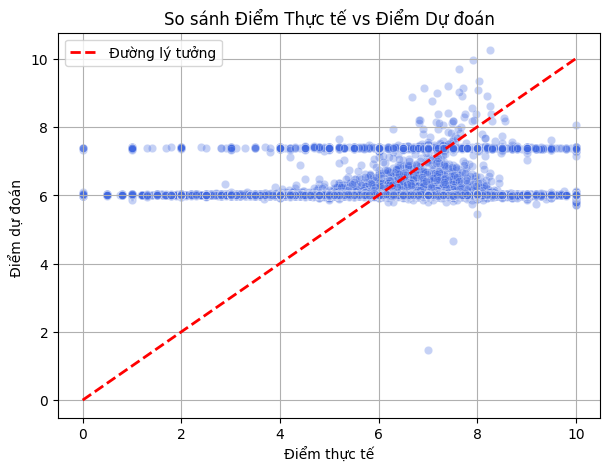

In [164]:
plt.figure(figsize=(7, 5)) #tạo khung dài 7inches cao 5 inches
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='royalblue')
#vec đồ thị với trục x là y_test trục y là y_pred, alpha là độ trong của điểm
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Đường lý tưởng')
#vẽ đường y = x

plt.xlabel('Điểm thực tế') #tên cột x
plt.ylabel('Điểm dự đoán ') #tên cột y
plt.title('So sánh Điểm Thực tế vs Điểm Dự đoán')
plt.legend() #hộp chú thích
plt.grid(True) #lưới
plt.show()

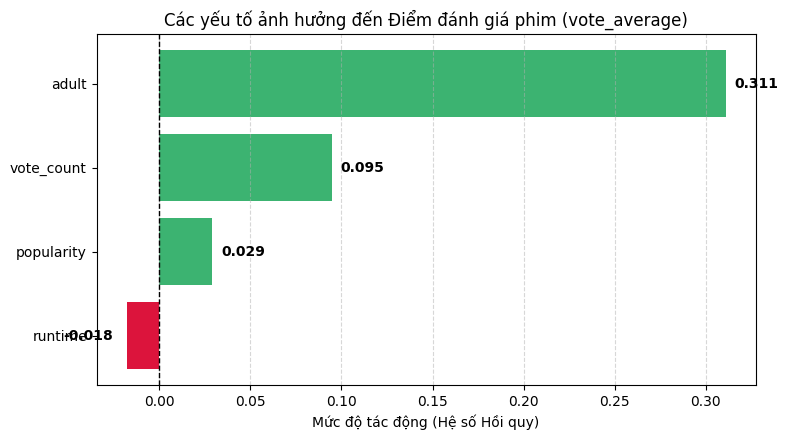

In [165]:
import pandas as pd
import matplotlib.pyplot as plt

# Lấy tên các cột và hệ số trọng số tương ứng từ mô hình
importance_df = pd.DataFrame({
    'Yếu tố': x.columns,
    'Trọng số': model.coef_
}).sort_values(by='Trọng số', ascending=True) #sắp xếp các trọng số tăng dần

# Vẽ biểu đồ cột nằm ngang (màu xanh là tác động tích cực, màu đỏ là tác động tiêu cực)
plt.figure(figsize=(8, 4.5))
colors = ['crimson' if val < 0 else 'mediumseagreen' for val in importance_df['Trọng số']]
bars = plt.barh(importance_df['Yếu tố'], importance_df['Trọng số'], color=colors)

# Vẽ đường x = 0 để chia ra tac động tích cực và tiêu cực
plt.axvline(0, color='black', linestyle='--', linewidth=1)

# Nhãn và tiêu đề
plt.xlabel('Mức độ tác động (Hệ số Hồi quy)')
plt.title('Các yếu tố ảnh hưởng đến Điểm đánh giá phim (vote_average)')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# In số cụ thể lên từng cột cho rõ ràng
for bar in bars:
    width = bar.get_width()
    offset = 0.005 if width >= 0 else -0.035
    plt.text(width + offset, bar.get_y() + bar.get_height()/2,
             f'{width:.3f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

- sau khi chạy model và kết quả khá tệ  thì lọc lại dữ liệu để test lại mô hình

Kích thước tập train: (14524, 4)
Kích thước tập test: (3631, 4)
Hệ số hồi quy mới(w):
Hệ số runtime: 0.1232
Hệ số vote_count: 0.1609
Hệ số popularity: 0.0350
Hệ số adult: 0.0054
Hệ số chặn(b): 6.5191
Sai số bình phương trung bình (MSE): 0.6618
Sai số tuyệt đối trung bình (MAE): 0.6556


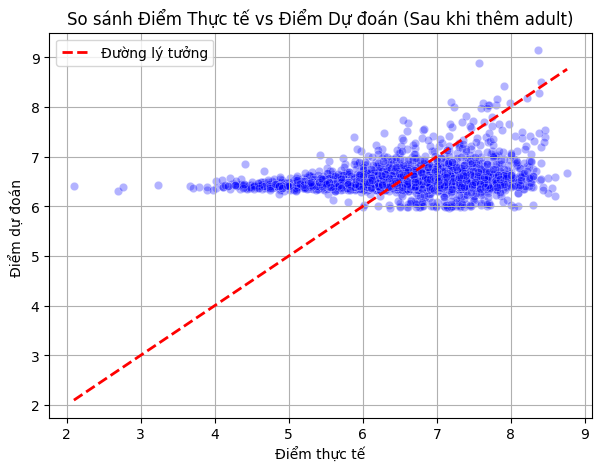

In [166]:
# Lọc các phim có vote_count từ 100 trở lên
dff_clean = dff[dff['vote_count'] >= 100].copy()

# Chuyển cột adult dạng bool thành kiểu int để đưa vào mô hình
dff_clean['adult'] = dff_clean['adult'].astype(int)

x = dff_clean[['runtime', 'vote_count', 'popularity', 'adult']]
y = dff_clean['vote_average']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"Kích thước tập train: {x_train.shape}")
print(f"Kích thước tập test: {x_test.shape}")

scaler = StandardScaler() # chuẩn hóa các cột về cùng thang đo

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

model = LinearRegression() # mô hình hồi quy tuyến tính
model.fit(x_train, y_train)

print("Hệ số hồi quy mới(w):")
for feature_name, coef in zip(x.columns, model.coef_):
    print(f"Hệ số {feature_name}: {coef:.4f}")

print(f"Hệ số chặn(b): {model.intercept_:.4f}")

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Sai số bình phương trung bình (MSE): {mse:.4f}")
print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")

# Vẽ biểu đồ phân tán kiểm tra kết quả dự đoán
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Đường lý tưởng')

plt.xlabel('Điểm thực tế')
plt.ylabel('Điểm dự đoán ')
plt.title('So sánh Điểm Thực tế vs Điểm Dự đoán (Sau khi thêm adult)')
plt.legend()
plt.grid(True)
plt.show()

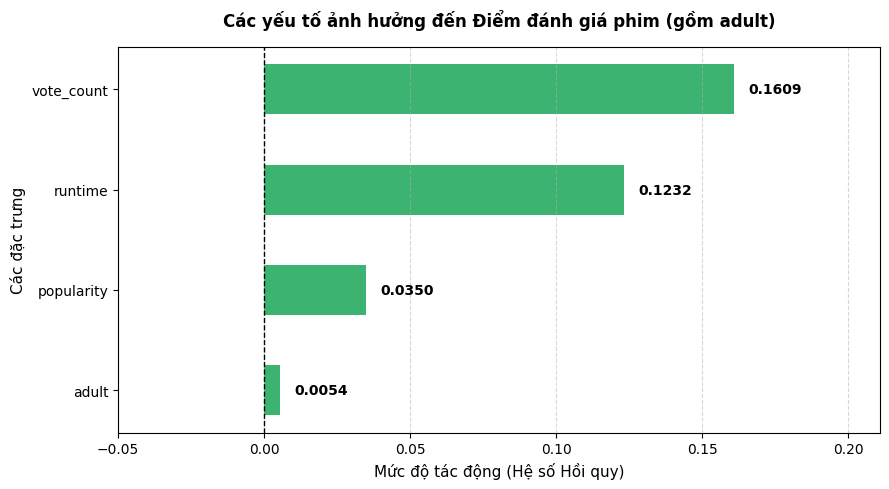

In [167]:
# 1. Lấy tên các cột và hệ số trọng số tương ứng từ mô hình mới (gồm cả adult)
importance_df = pd.DataFrame({
    'Yếu tố': x.columns,
    'Trọng số': model.coef_
}).sort_values(by='Trọng số', ascending=True)

# 2. Vẽ biểu đồ cột nằm ngang
plt.figure(figsize=(9, 5))
colors = ['crimson' if val < 0 else 'mediumseagreen' for val in importance_df['Trọng số']]
bars = plt.barh(importance_df['Yếu tố'], importance_df['Trọng số'], color=colors, height=0.5)

# Vẽ đường mốc 0
plt.axvline(0, color='black', linestyle='--', linewidth=1)

# Nhãn và tiêu đề
plt.xlabel('Mức độ tác động (Hệ số Hồi quy)', fontsize=11)
plt.ylabel('Các đặc trưng', fontsize=11)
plt.title('Các yếu tố ảnh hưởng đến Điểm đánh giá phim (gồm adult)', fontsize=12, fontweight='bold', pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Nới rộng giới hạn trục hoành một chút để tránh nhãn text bị tràn viền
max_val = importance_df['Trọng số'].abs().max()
plt.xlim(min(0, importance_df['Trọng số'].min()) - 0.05, importance_df['Trọng số'].max() + 0.05)

# In số cụ thể lên từng cột
for bar in bars:
    width = bar.get_width()
    offset = 0.005 if width >= 0 else -0.025
    plt.text(width + offset, bar.get_y() + bar.get_height()/2,
             f'{width:.4f}', va='center', ha='left' if width >= 0 else 'right',
             fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

- sau 2 lần lọc và xử lý dữ liệu thì mô hình dự đoán vẫn chưa tốt lắm

-> Có thể do dùng ít feature nê model học chưa chính xác. Có thể tiến hành xử lý lại dữ liệu để lấy nhiều cột feature hơn

In [168]:
import ast
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

# 1. Lọc cột & Xử lý trùng lặp ban đầu
cols = [
    'budget',
    'revenue',
    'popularity',
    'vote_average',
    'vote_count',
    'original_language',
    'runtime',
    'release_date',
    'genres',
    'adult'
]

# Tạo bản sao và loại bỏ trùng lặp + dòng thiếu release_date
df_simple = df[cols].dropna(subset=['release_date']).copy()

# QUAN TRỌNG: Reset index để tránh lỗi tràn dòng NaN khi concat
df_simple = df_simple.reset_index(drop=True)

# 2. Xử lý giá trị 0 và điền missing values cho các cột số
for col in ['budget', 'revenue', 'runtime']:
    df_simple[col] = df_simple[col].replace(0, pd.NA).fillna(df_simple[col].median())

df_simple['genres'] = df_simple['genres'].fillna('Unknown')
df_simple['original_language'] = df_simple['original_language'].fillna('other')

# 3. Trích xuất Năm & Tháng phát hành
df_simple['release_date'] = pd.to_datetime(df_simple['release_date'], errors='coerce')
df_simple['release_year'] = df_simple['release_date'].dt.year
df_simple['release_month'] = df_simple['release_date'].dt.month
df_simple = df_simple.drop(columns=['release_date'])

# 4. Mã hóa genres (Multi-label)
def parse_genres(x):
    if isinstance(x, str):
        try:
            parsed = ast.literal_eval(x)
            if isinstance(parsed, list):
                return [d['name'] if isinstance(d, dict) else d for d in parsed]
        except Exception:
            pass
    return ['Unknown']

mlb = MultiLabelBinarizer()
genres_encoded = pd.DataFrame(
    mlb.fit_transform(df_simple['genres'].apply(parse_genres)),
    columns=[f'genre_{c}' for c in mlb.classes_],
    index=df_simple.index  # Đảm bảo đồng bộ index
)

# 5. Mã hóa Ngôn ngữ (Sử dụng df_simple thay vì df gốc)
top_languages = df_simple['original_language'].value_counts().head(5).index
df_simple['lang_grouped'] = df_simple['original_language'].apply(
    lambda x: x if x in top_languages else 'other'
)

lang_encoded = pd.get_dummies(
    df_simple['lang_grouped'], prefix='lang', dtype=int
)
lang_encoded.index = df_simple.index  # Đảm bảo đồng bộ index


# 6. Gộp lại tập dữ liệu hoàn chỉnh
df_final = pd.concat(
    [
        df_simple.drop(columns=['genres', 'original_language', 'lang_grouped']),
        genres_encoded,
        lang_encoded,
    ],
    axis=1,
)

# 1. Tạo đặc trưng tỉ lệ ROI (Return on Investment)
# Tránh lỗi chia cho 0 bằng cách thay budget = 0 thành NaN (hoặc dùng budget đã được làm sạch)
df_final['roi'] = df_final['revenue'] / df_final['budget']

# 2. Tạo đặc trưng độ hot trên mỗi lượt vote
df_final['pop_per_vote'] = df_final['popularity'] / (
    df_final['vote_count'] + 1
)

# 3. Biến đổi Log1p cho 2 đặc trưng mới (vì ROI và Pop/Vote thường bị lệch phải rất mạnh)
df_final['roi_log'] = np.log1p(df_final['roi'].clip(lower=0))  # clip để tránh ROI âm gây lỗi log
df_final['pop_per_vote_log'] = np.log1p(df_final['pop_per_vote'])

# Xử lý các giá trị vô cùng (inf) hoặc NaN phát sinh nếu có
df_final['roi_log'] = df_final['roi_log'].fillna(0)
df_final['pop_per_vote_log'] = df_final['pop_per_vote_log'].fillna(0)

# Bỏ các cột ROI gốc chưa log
df_final = df_final.drop(columns=['roi', 'pop_per_vote'])

# 7. Kiểm tra kết quả
print(f"Kích thước dữ liệu mới: {df_final.shape}")
print(df_final.info())
print("\nKiểm tra số dòng trống:")
print(df_final.isnull().sum())
print("\nKiểm tra số dòng bị trùng lặp:", df_final.duplicated().sum())
df_final = df_final.drop_duplicates()
print("Kiểm tra lại số dòng bị trùng: ", df_final.duplicated().sum())


/tmp/ipykernel_801/597755256.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_simple[col] = df_simple[col].replace(0, pd.NA).fillna(df_simple[col].median())


Kích thước dữ liệu mới: (291167, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 291167 entries, 0 to 291166
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   budget            291167 non-null  float64
 1   revenue           291167 non-null  float64
 2   popularity        291167 non-null  float64
 3   vote_average      291167 non-null  float64
 4   vote_count        291167 non-null  int64  
 5   runtime           291167 non-null  float64
 6   adult             291167 non-null  bool   
 7   release_year      291167 non-null  int32  
 8   release_month     291167 non-null  int32  
 9   genre_Unknown     291167 non-null  int64  
 10  lang_de           291167 non-null  int64  
 11  lang_en           291167 non-null  int64  
 12  lang_es           291167 non-null  int64  
 13  lang_fr           291167 non-null  int64  
 14  lang_ja           291167 non-null  int64  
 15  lang_other        291167 non-nu

Kích thước tập train: (4416, 17)
Kích thước tập test: (1105, 17)
Hệ số hồi quy mới(w):
Hệ số budget: -0.1995
Hệ số revenue: -0.0544
Hệ số popularity: -0.0156
Hệ số vote_count: 0.1927
Hệ số runtime: 0.2094
Hệ số adult: 0.0087
Hệ số release_year: -0.2038
Hệ số release_month: 0.0371
Hệ số genre_Unknown: 0.0000
Hệ số lang_de: 0.0238
Hệ số lang_en: -0.0871
Hệ số lang_es: 0.0484
Hệ số lang_fr: -0.0093
Hệ số lang_ja: 0.0857
Hệ số lang_other: 0.0577
Hệ số roi_log: 0.0030
Hệ số pop_per_vote_log: 0.0267
Hệ số chặn(b): 6.5468
Sai số bình phương trung bình (MSE): 0.3870
Sai số tuyệt đối trung bình (MAE): 0.4739


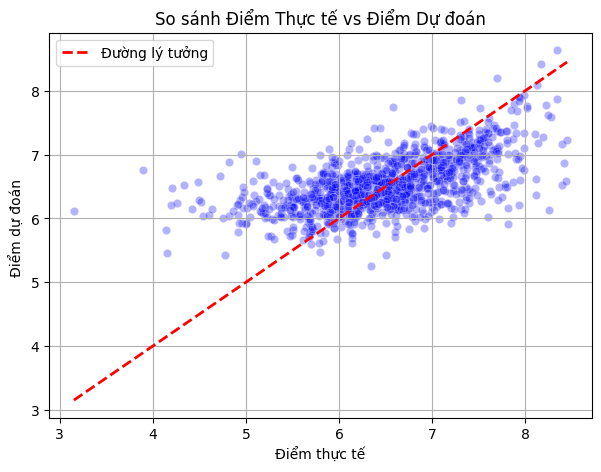

In [169]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Lọc các phim có vote_count từ 350 trở lên
df_final = df_final[df_final['vote_count'] >= 350].copy()

# Chuyển cột adult dạng bool thành kiểu int để đưa vào mô hình
df_final['adult'] = df_final['adult'].astype(int)

def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Chỉ giữ lại các giá trị nằm trong khoảng an toàn
    df_filtered = df[
        (df[column] >= lower_bound) & (df[column] <= upper_bound)
    ]
    return df_filtered


# Áp dụng cho danh sách các cột số trong tập dữ liệu của bạn
num_cols = ['budget', 'revenue', 'popularity', 'vote_count', 'runtime']

for col in num_cols:
    df_final = remove_outliers_iqr(df_final, col)

# Reset lại index sau khi xóa bớt dòng
df_final = df_final.reset_index(drop=True)

x = df_final.drop(columns=['vote_average'])

# Xử lý triệt để giá trị vô cùng (inf / -inf) phát sinh từ phép tính ROI thành 0
x = x.replace([np.inf, -np.inf], 0)

y = df_final['vote_average']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"Kích thước tập train: {x_train.shape}")
print(f"Kích thước tập test: {x_test.shape}")

scaler = StandardScaler() # chuẩn hóa các cột về cùng thang đo

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

model = LinearRegression() # mô hình hồi quy tuyến tính
model.fit(x_train, y_train)

print("Hệ số hồi quy mới(w):")
for feature_name, coef in zip(x.columns, model.coef_):
    print(f"Hệ số {feature_name}: {coef:.4f}")

print(f"Hệ số chặn(b): {model.intercept_:.4f}")

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Sai số bình phương trung bình (MSE): {mse:.4f}")
print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")

# Vẽ biểu đồ phân tán kiểm tra kết quả dự đoán
plt.figure(figsize=(7, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Đường lý tưởng')

plt.xlabel('Điểm thực tế')
plt.ylabel('Điểm dự đoán ')
plt.title('So sánh Điểm Thực tế vs Điểm Dự đoán')
plt.legend()
plt.grid(True)
plt.show()